# Topic 8 - Advanced Data Visualisation

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Discuss the underpinning theory of graphs and networks
2. Use algorithms to traverse graphs and to identify shortest and optimal routes
3. Use the Python programming language and libraries such as Matplotlib and NetworkX to build and visualise networks
4. Use the acquired knowledge and skills to solve real-world network-related problems and to develop and visualise large and complex networks
5. Design and develop visualisation tools presenting large and multidimensional datasets
6. Evaluate visualisation approaches based on their aesthetic, usefulness and the ability to convey information
7. Work with datasets with various dimensions and sizes
8. Choose appropriate visualisation approaches based on the types of the data points

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 8.0 Introduction </h2>
</div>

### Reading: Why graphs and a graph for every problem

Brath, R. and D. Jonker. '[Graph analysis and visualization: discovering business opportunity in linked data](https://ebookcentral.proquest.com/lib/londonww/detail.action?docID=1895654).' (Hoboken: Wiley, 2015). Chapter 1: Why Graphs (pages 3 to 26), Chapter 2: A Graph for Every Problem (pages 27 to 49)

`Alternative Link (Google Books - Preview)`
> * https://books.google.com.sg/books?id=pkPxBQAAQBAJ&printsec=frontcover&source=gbs_ge_summary_r&cad=0#v=onepage&q&f=false

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 8.1 Building and Visualising Graphs </h2>
</div>

### Programming Language Support

- Many programming languages provide the necessary functionality to support graphs, in most cases as data structures. These include C++, Java, and others
- In Python, the graph functionality is provided by the library NetworkX
- It allows us to process graphs as data structures and to visualise them as diagrams
- With this library, we can:
  * build and visualise networks
  * analyse their properties
  * utilise graph algorithms



### Creating Graphs with Python and NetworkX

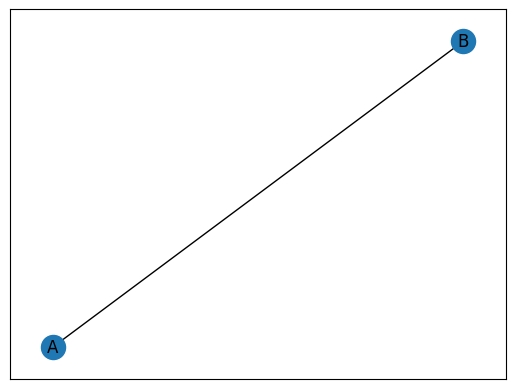

In [16]:
# Simple Example

# import the networkx module (and also matplotlib)
import networkx as nx
import matplotlib.pyplot as plt

# create an object (empty graph)
MyGraph = nx.Graph()

# from this point onwards, we can start adding nodes and connect them with edges

# add two nodes named A and B
MyGraph.add_node('A')
MyGraph.add_node('B')

# connect nodes A and B with an edge
MyGraph.add_edge('A','B')

# result is an undirected graph with two connected nodes
nx.draw_networkx(MyGraph)
plt.show()

### Types of Graphs

NetworkX allows us to create various types of graphs

- Undirected graph
    * All edges are bi-directional (symmetrical)
    * Edges represent a two-way relation
    * The edges can be traversed in both directions
    * Example: Facebook
- Directed graph
    * Usually represented with arrows
    * Edges can be represented as ordered pairs (A,B)
    * Traversing the edges in the directed graph is restricted to one direction only
    * Example: Twitter (X follows Y, but Y does not follow X)
 - Complete graph
    * In this type of graph, every possible pair of nodes is connected to a unique edge
    * As a data structure, it is not different from an undirected graph
    * Except all possible edges are connected
    * Complete graph with N nodes has N x (N-1) / 2 edges
- Weighted graph
    * From this type of graph, a value is assigned to every edge
    * The value might represent distance, time, cost, or any numerical value which characterises the transition from one node to another


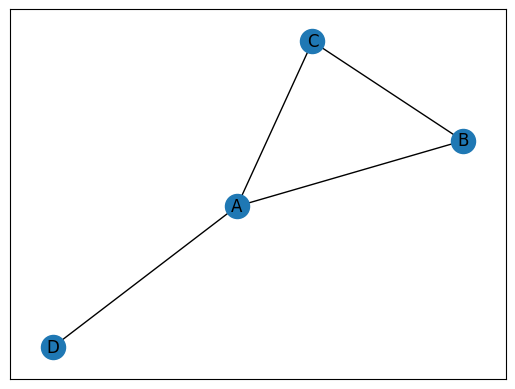

In [17]:
# Undirected graph

import matplotlib.pyplot as plt
import networkx as nx

MyG1 = nx.Graph()

MyG1.add_node('A')
MyG1.add_node('B')
MyG1.add_node('C')
MyG1.add_node('D')

MyG1.add_edge('A', 'B')
MyG1.add_edge('A', 'C')
MyG1.add_edge('B', 'C')
MyG1.add_edge('A', 'D')

nx.draw_networkx(MyG1)
plt.show()

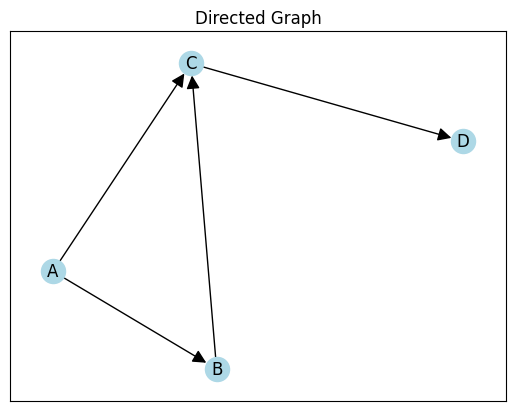

In [18]:
# Directed graph

import matplotlib.pyplot as plt
import networkx as nx

# Create a directed graph using DiGraph instead of Graph
MyDiG = nx.DiGraph()

# Add nodes
MyDiG.add_node('A')
MyDiG.add_node('B')
MyDiG.add_node('C')
MyDiG.add_node('D')

# Add directed edges (arrows will show direction)
MyDiG.add_edge('A', 'B')  # A -> B
MyDiG.add_edge('A', 'C')  # A -> C
MyDiG.add_edge('B', 'C')  # B -> C
MyDiG.add_edge('C', 'D')  # C -> D

# Draw the directed graph
nx.draw_networkx(MyDiG, with_labels=True, node_color='lightblue', 
                 arrows=True, arrowsize=20)
plt.title("Directed Graph")
plt.show()

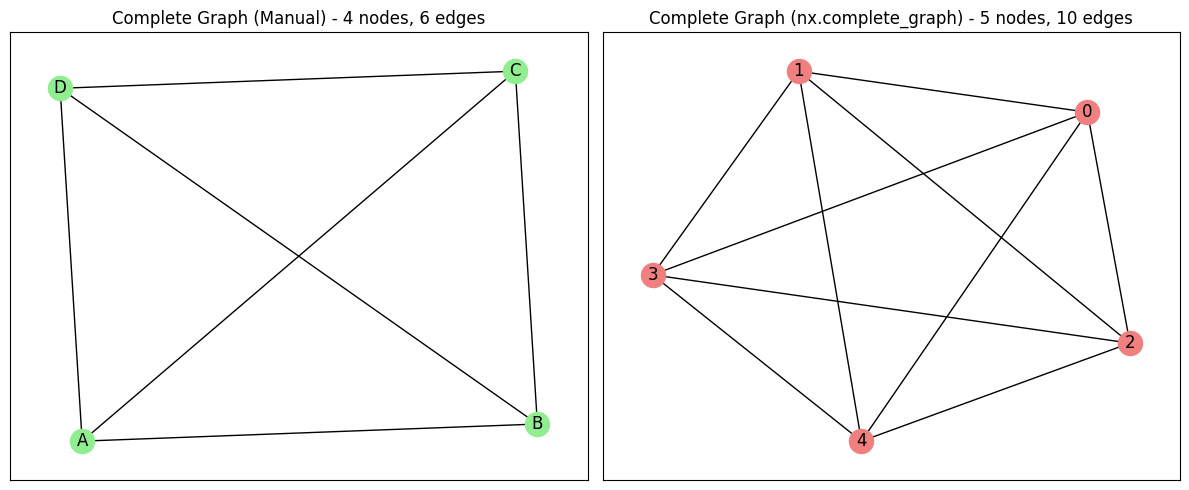

Graph 1: 4 nodes, 6 edges
Graph 2: 5 nodes, 10 edges


In [19]:
# Complete graph

import matplotlib.pyplot as plt
import networkx as nx

# Option 1: Build manually from undirected graph
MyCompleteG1 = nx.Graph()
MyCompleteG1.add_nodes_from(['A', 'B', 'C', 'D'])

# Add all possible edges to make it complete
MyCompleteG1.add_edges_from([
    ('A', 'B'), ('A', 'C'), ('A', 'D'),
    ('B', 'C'), ('B', 'D'),
    ('C', 'D')
])

# Option 2: Use NetworkX's built-in complete_graph function
MyCompleteG2 = nx.complete_graph(5)  # Creates complete graph with 5 nodes (0,1,2,3,4)

# Display both graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nx.draw_networkx(MyCompleteG1, with_labels=True, node_color='lightgreen', ax=axes[0])
axes[0].set_title("Complete Graph (Manual) - 4 nodes, 6 edges")

nx.draw_networkx(MyCompleteG2, with_labels=True, node_color='lightcoral', ax=axes[1])
axes[1].set_title("Complete Graph (nx.complete_graph) - 5 nodes, 10 edges")

plt.tight_layout()
plt.show()

# Verify: Complete graph with N nodes has N*(N-1)/2 edges
print(f"Graph 1: {MyCompleteG1.number_of_nodes()} nodes, {MyCompleteG1.number_of_edges()} edges")
print(f"Graph 2: {MyCompleteG2.number_of_nodes()} nodes, {MyCompleteG2.number_of_edges()} edges")

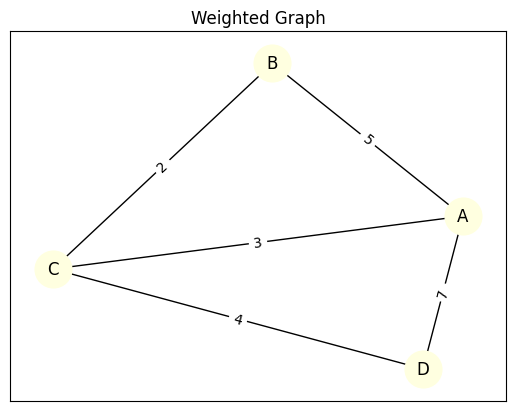

Shortest path from A to D (by weight): ['A', 'D']
Shortest path length: 7


In [20]:
# Weighted graph

import matplotlib.pyplot as plt
import networkx as nx

# Create a weighted graph (similar to undirected graph, but with weight attribute)
MyWeightedG = nx.Graph()

# Add nodes
MyWeightedG.add_node('A')
MyWeightedG.add_node('B')
MyWeightedG.add_node('C')
MyWeightedG.add_node('D')

# Add edges with weight attribute
MyWeightedG.add_edge('A', 'B', weight=5)
MyWeightedG.add_edge('A', 'C', weight=3)
MyWeightedG.add_edge('B', 'C', weight=2)
MyWeightedG.add_edge('A', 'D', weight=7)
MyWeightedG.add_edge('C', 'D', weight=4)

# Get edge weights for display
edge_labels = nx.get_edge_attributes(MyWeightedG, 'weight')

# Draw the graph
pos = nx.spring_layout(MyWeightedG)  # Get positions for nodes
nx.draw_networkx(MyWeightedG, pos, with_labels=True, node_color='lightyellow', node_size=700)
nx.draw_networkx_edge_labels(MyWeightedG, pos, edge_labels=edge_labels)
plt.title("Weighted Graph")
plt.show()

# Calculate shortest path based on weight
print("Shortest path from A to D (by weight):", nx.shortest_path(MyWeightedG, 'A', 'D', weight='weight'))
print("Shortest path length:", nx.shortest_path_length(MyWeightedG, 'A', 'D', weight='weight'))

### Other Types of Graphs

- Tree
    * In this case, the graph has a designated root node and every edge points towards the root node (in-tree) or away from the root node (out-tree)
- Directed Acyclic Graphs (DAG)
    * These are directed graphs without cycles. All trees are DAGs but not all DAGs are trees


### Graph Attributes

- We use attributes to add properties to the nodes and eges
    * These properties help to represent, or to model, a real-world network
- Examples
    * Weight of edges (distance, time, cost, others)
    * Colour of nodes/edges
    * Co-ordinates of nodes
- Attributes are stored as dictionaries, where:
    * key is the node name, or the (ordered) pair of the edge
    * value is the attribute


### More on Graph Attributes

- Attributes can be specified when adding a new node/edge (preferred choice) or at a later stage (also possible):
    * `MyGraph.add_node('A', A1=1)` (preferred)
    *  `nx.set_node_attributes(MyGraph, values={'A':100, 'B':35, 'C':2, 'D':4}, name='A1')`
- If needed, attributes can be extracted from the graph data structure and stored in a dictionary and/or a list
    * `NodeDictionary=nx.get_node_attributes(MyGraph,'A1')` (dictionary)
    * `NodeList=NodeDictionary.values()` (list)
- Printing the contents of the dictionary and the list highlights how these two data structures organise and store data
    * Dictionary:
        - Input: `print(NodeDictionary)`
        - Output: {'A':100, 'B':35, 'C':2,  'D':4}
    * List:
        - Input: `print(NodeList)`
        - Output: [100, 25, 2, 4]

Node Dictionary:  {'A': 100, 'B': 35, 'C': 2, 'D': 4}
Node List:  dict_values([100, 35, 2, 4])
Node A has attributes {'A1': 100}
Node B has attributes {'A1': 35}
Node C has attributes {'A1': 2}
Node D has attributes {'A1': 4}


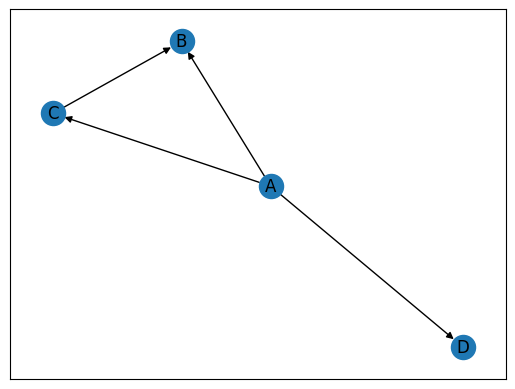

In [21]:
# Let's try out the code to do this

import matplotlib.pyplot as plt
import networkx as nx

MyGraph = nx.DiGraph()

# Attributes can be specified when adding a new node/edge (preferred choice)
MyGraph.add_node('A', A1=1)  
MyGraph.add_node('B', A1=2)
MyGraph.add_node('C', A1=3)
MyGraph.add_node('D', A1=4)

# Attributes can also be added at a later stage (also possible)
nx.set_node_attributes(MyGraph, values={'A':100, 'B':35, 'C':2, 'D':4}, name='A1')
# nx.set_node_attributes(MyGraph, values={'A':110}, name='A1')  # update one value
# nx.set_node_attributes(MyGraph, values={'A':220, 'B':350}, name='A2')  # add new attribute

# Add edges to connect the nodes (optional)
MyGraph.add_edge('A', 'B')
MyGraph.add_edge('A', 'C')
MyGraph.add_edge('A', 'D')
MyGraph.add_edge('C', 'B')

# If needed, attributes can be extracted and stored in a dictionary and/or a list
NodeDictionary = nx.get_node_attributes(MyGraph,'A1')
NodeList = NodeDictionary.values()
print('Node Dictionary: ', NodeDictionary)
print('Node List: ', NodeList)

# Alternatively, you can iterate over nodes and their attributes
for node, attr in MyGraph.nodes(data=True):
    print(f"Node {node} has attributes {attr}")

nx.draw_networkx(MyGraph)
plt.show()


### Isomorphic Graphs

- Nodes in a typical graph in most cases do not have information about their co-ordinates
- Even if this information exists, it is usually "*abstracted out*"
- As a result, a graph can be visualised differently, based on the position of its nodes
- These different "versions", or layouts, of the same graph are called *Isomorphic Graphs*
- In some cases, in practice, there is a requirement for the edges not to cross each other (e.g., designing a single layer circuit board). This type of graphs are called planar
- It is possible to instruct NetworkX to follow this requirement:
    * `MyGraph = nx.Graph()`
    * `Position = nx.planar_layout(MyGraph)`
- In the new layout, edges will not intersect
- The original graph and its Planar version are both Isomorphic Graphs

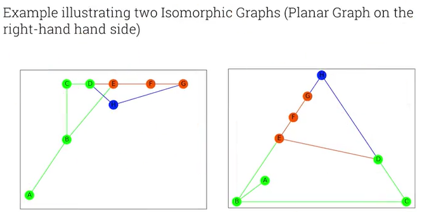

- It is not always possible to obtain a Planar Graph (e.g., a complete graph with 5 nodes and 10 edges)


### Graph Layouts

- A graph can have multiple layouts
    * All layouts retain the same connectivity
- These layouts can be based on
    * Aesthetics
    * Need to emphasize connectivity of specific nodes
    * Need to emphasize specific connections
- The NetworkX library provides a number of different layours to choose from

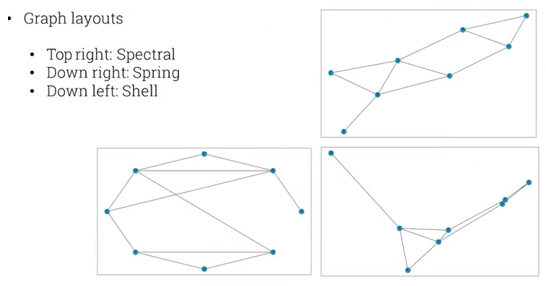

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 8.2 Developing Networks </h2>
</div>

Next, we discuss the practical aspects of building and processing networks. 

More specifically, we will focus on:
* Main operations
    - Traversing a network -- Visiting all network nodes once
    - Finding optimal (shortest) path -- Using algorithms
* Real-world examples
* Challenges faced when visualising networks    

### 8.2.1 Main Operations: Traversing a Network

Graphs (and networks) are non-linear data structure, unlike arrays and lists
* As a result, traversing them is not a trivial task
* In addition, there are more than one way to conduct the traversal

Most popular traversal algorithms are:
1. **Breadth-first Search (BFS)** -- Visit all neighbouring nodes connected to the root node (starting point), then select one of the nodes already visited and visit all nodes connected to it. Repeat until all nodes are visited
2. **Depth-first Search (DFS)** -- - Select one node connected to the 'root' node and then visit all nodes in that direction until the last node at the lowest level is reached. Select the next node connected to the root node and repeat the steps



Both BFS and DFS treat the nodes as organised in levels
* Highest level is a 'root' node, which acts as a starting point for the algorithms

Both the BFS and DFS algorithms repeat their steps until all nodes are visited
* To avoid visiting a node more than once, visited nodes are marked (crucial when working with cyclic graphs)
* The result of both algorithms is a sequence of nodes arranged in the order they are visited
    - NetworkX can generate and visualise these sequences 

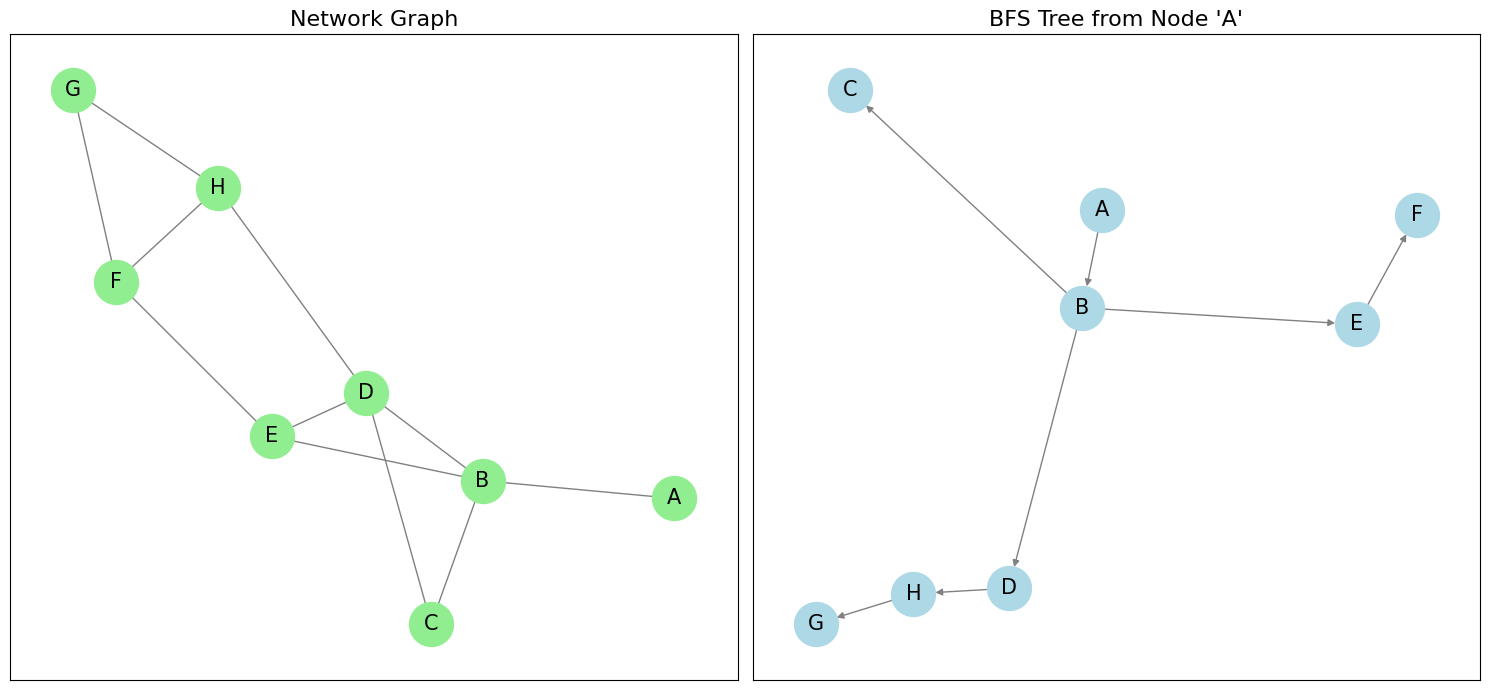

In [22]:
# Additional - Plotting Breadth-first Search (BFS) Tree
# BFS = nx.bfs_tree(MyGraph,'A')

import matplotlib.pyplot as plt
import networkx as nx

MyGraph = nx.Graph()

# Add nodes
MyGraph.add_nodes_from(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'])

# Add edges
MyGraph.add_edges_from([
    ('A', 'B'), ('B', 'C'), ('B', 'D'), ('B', 'E'),
    ('C', 'D'), ('D', 'E'), ('D', 'H'), ('E', 'F'),
    ('F', 'G'), ('F', 'H'), ('G', 'H')
])

# Create the BFS tree from node 'A'
BFS = nx.bfs_tree(MyGraph, 'A')

# Set up the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Plot the network graph on the first subplot
nx.draw_networkx(MyGraph, 
                 with_labels=True, 
                 node_color='lightgreen', 
                 edge_color='gray', 
                 node_size=1000, font_size=15, 
                 ax=axes[0])
axes[0].set_title("Network Graph", fontsize=16)

# Plot the BFS tree on the second subplot
nx.draw_networkx(BFS, 
                 with_labels=True, 
                 node_color='lightblue', 
                 edge_color='gray', 
                 node_size=1000, 
                 font_size=15, 
                 ax=axes[1])
axes[1].set_title("BFS Tree from Node 'A'", fontsize=16)

# Display the plot
plt.tight_layout()
plt.show()

# Note: Let's try applying Breadth-First Search manually


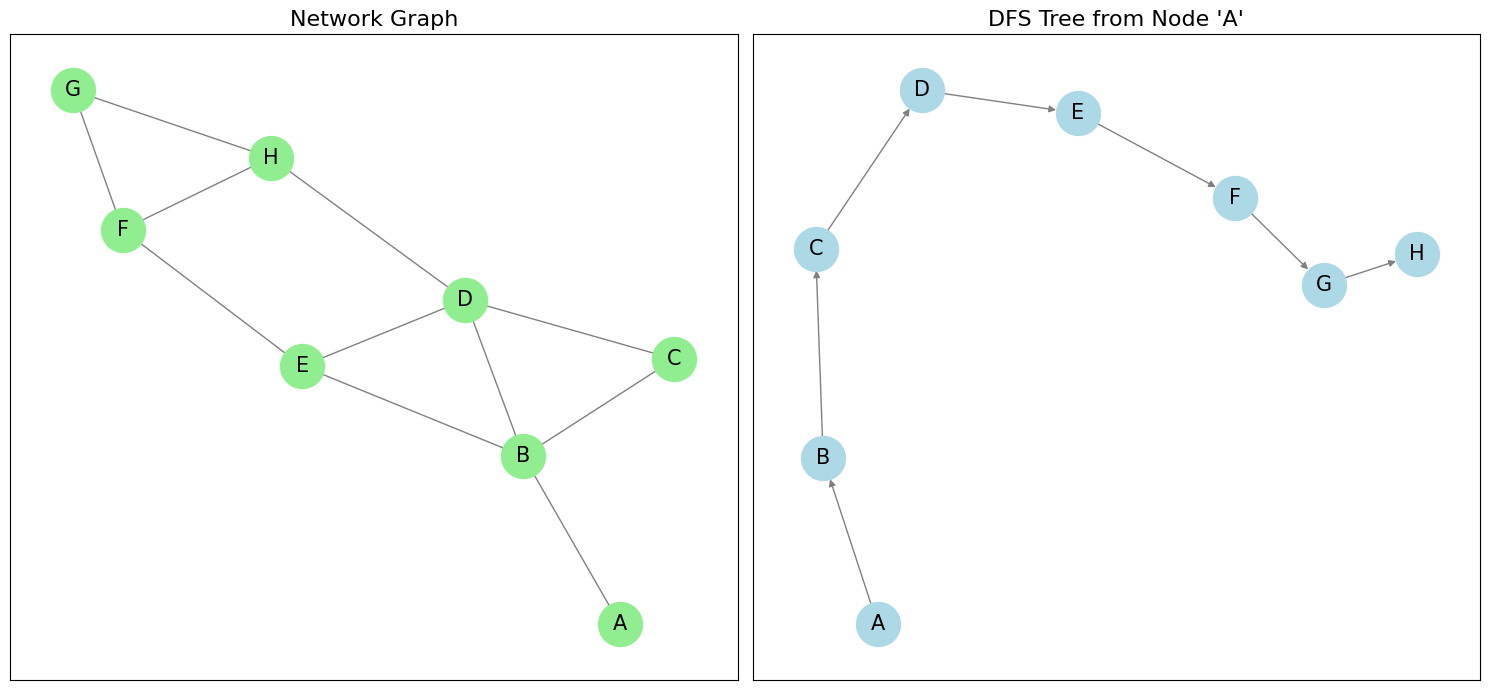

In [23]:
# Additional (Optional) - Plotting Depth-first Search (DFS) Tree
# DFS = nx.dfs_tree(MyGraph,'A')   # simply replace the one for BFS

import matplotlib.pyplot as plt
import networkx as nx

MyGraph = nx.Graph()

# Add nodes
MyGraph.add_nodes_from(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'])

# Add edges
MyGraph.add_edges_from([
    ('A', 'B'), ('B', 'C'), ('B', 'D'), ('B', 'E'),
    ('C', 'D'), ('D', 'E'), ('D', 'H'), ('E', 'F'),
    ('F', 'G'), ('F', 'H'), ('G', 'H')
])

# Create the DFS tree from node 'A'
DFS = nx.dfs_tree(MyGraph, 'A')

# Set up the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Plot the network graph on the first subplot
nx.draw_networkx(MyGraph, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=1000, font_size=15, ax=axes[0])
axes[0].set_title("Network Graph", fontsize=16)

# Plot the BFS tree on the second subplot
nx.draw_networkx(DFS, with_labels=True, node_color='lightblue', edge_color='gray', node_size=1000, font_size=15, ax=axes[1])
axes[1].set_title("DFS Tree from Node 'A'", fontsize=16)

# Display the plot
plt.tight_layout()
plt.show()

# Note: Let's try applying Depth-First Search manually


### 8.2.2 Main Operations: Finding the Optimal (Shortest) Path

- Finding the shortest, or most optimal, path in a graph or network has applications in many areas in practice (e.g., Google Maps)
- Several algorithms exist, with Dijkstra algorithm being one of the most popular
- The optimal (shortest) path between two nodes can be based on the number of nodes, or the weights assigned to the edges
- The network example demonstrated later illustrates the shortest path algorithm

### 8.2.3 Real-World Examples

Real-world networks usually have a significant number of nodes and edges

Working with large networks brings a number of challenges, including:
* Storing the network's nodes and edges as graph data structure in the computer's memory
* Applying computationally intensive algorithms to process large amounts of data, possibly forming a so-called 'bottleneck'
* Visualising (plotting) a large number of connected nodes
 


#### *1. Project Plot Football League*

This example generates a graph representing a number of football teams (nodes) and the games they played (edges)
- Relatively high number of nodes and edges, 115 and 613 respectively
- Network visualised by using Python and NetworkX

**Exercise**:
- Download the code/data files -- https://networkx.org/documentation/stable/auto_examples/graph/plot_football.html
- Initialise the graph object by using the 'parse_gml' method
- Visualise the graph using different layouts (spring, spectral and shell) and different node sizes to identify optimal view
- Print additional information about the graph by using the methods: 'number_of_nodes', 'number_of_edges' and 'node_connectivity' 


The file football.gml contains the network of American football games
between Division IA colleges during regular season Fall 2000, as compiled
by M. Girvan and M. Newman.  The nodes have values that indicate to which
conferences they belong.  The values are as follows:

  0 = Atlantic Coast
  1 = Big East
  2 = Big Ten
  3 = Big Twelve
  4 = Conference USA
  5 = Independents
  6 = Mid-American
  7 = Mountain West
  8 = Pacific Ten
  9 = Southeastern
 10 = Sun Belt
 11 = Western Athletic

If you make use of these data, please cite M. Girvan and M. E. J. Newman,
Community structure in social and biological networks,
Proc. Natl. Acad. Sci. USA 99, 7821-7826 (2002).

Correction: Two edges were erroneously duplicated in this data set, and
have been removed (21 SEP 2014)

BrighamYoung         12
FloridaState         12
Iowa                 12
KansasState          12
NewMexico            11
TexasTech            12
PennState            12
SouthernCalifornia   12
ArizonaState         11
SanDie

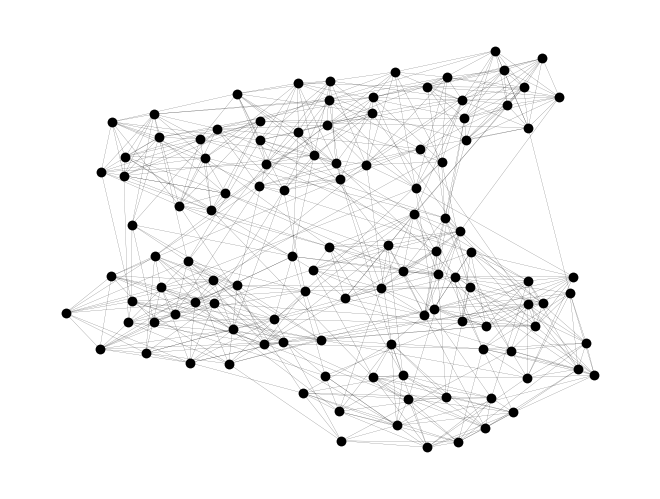

In [32]:
# Project Plot Football League

### Instructions:
### Please access this URL and copy/paste the code provided into this cell:
### https://networkx.org/documentation/stable/auto_examples/graph/plot_football.html

### Insert a copy of the code here and run it
import urllib.request
import io
import zipfile

import matplotlib.pyplot as plt
import networkx as nx

# The original URL is no longer accessible, using alternative approach
# Option 1: Try with updated headers to avoid 403 error
url = "http://www-personal.umich.edu/~mejn/netdata/football.zip"

req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
sock = urllib.request.urlopen(req)  # open URL with headers
s = io.BytesIO(sock.read())  # read into BytesIO "file"
sock.close()

zf = zipfile.ZipFile(s)  # zipfile object
txt = zf.read("football.txt").decode()  # read info file
gml = zf.read("football.gml").decode()  # read gml data
# throw away bogus first line with # from mejn files
gml = gml.split("\n")[1:]
G = nx.parse_gml(gml)  # parse gml data

print(txt)
# print degree for each team - number of games
for n, d in G.degree():
    print(f"{n:20} {d:2}")

options = {"node_color": "black", "node_size": 50, "linewidths": 0, "width": 0.1}

pos = nx.spring_layout(G, seed=1969)  # Seed for reproducible layout
nx.draw(G, pos, **options)
plt.show()

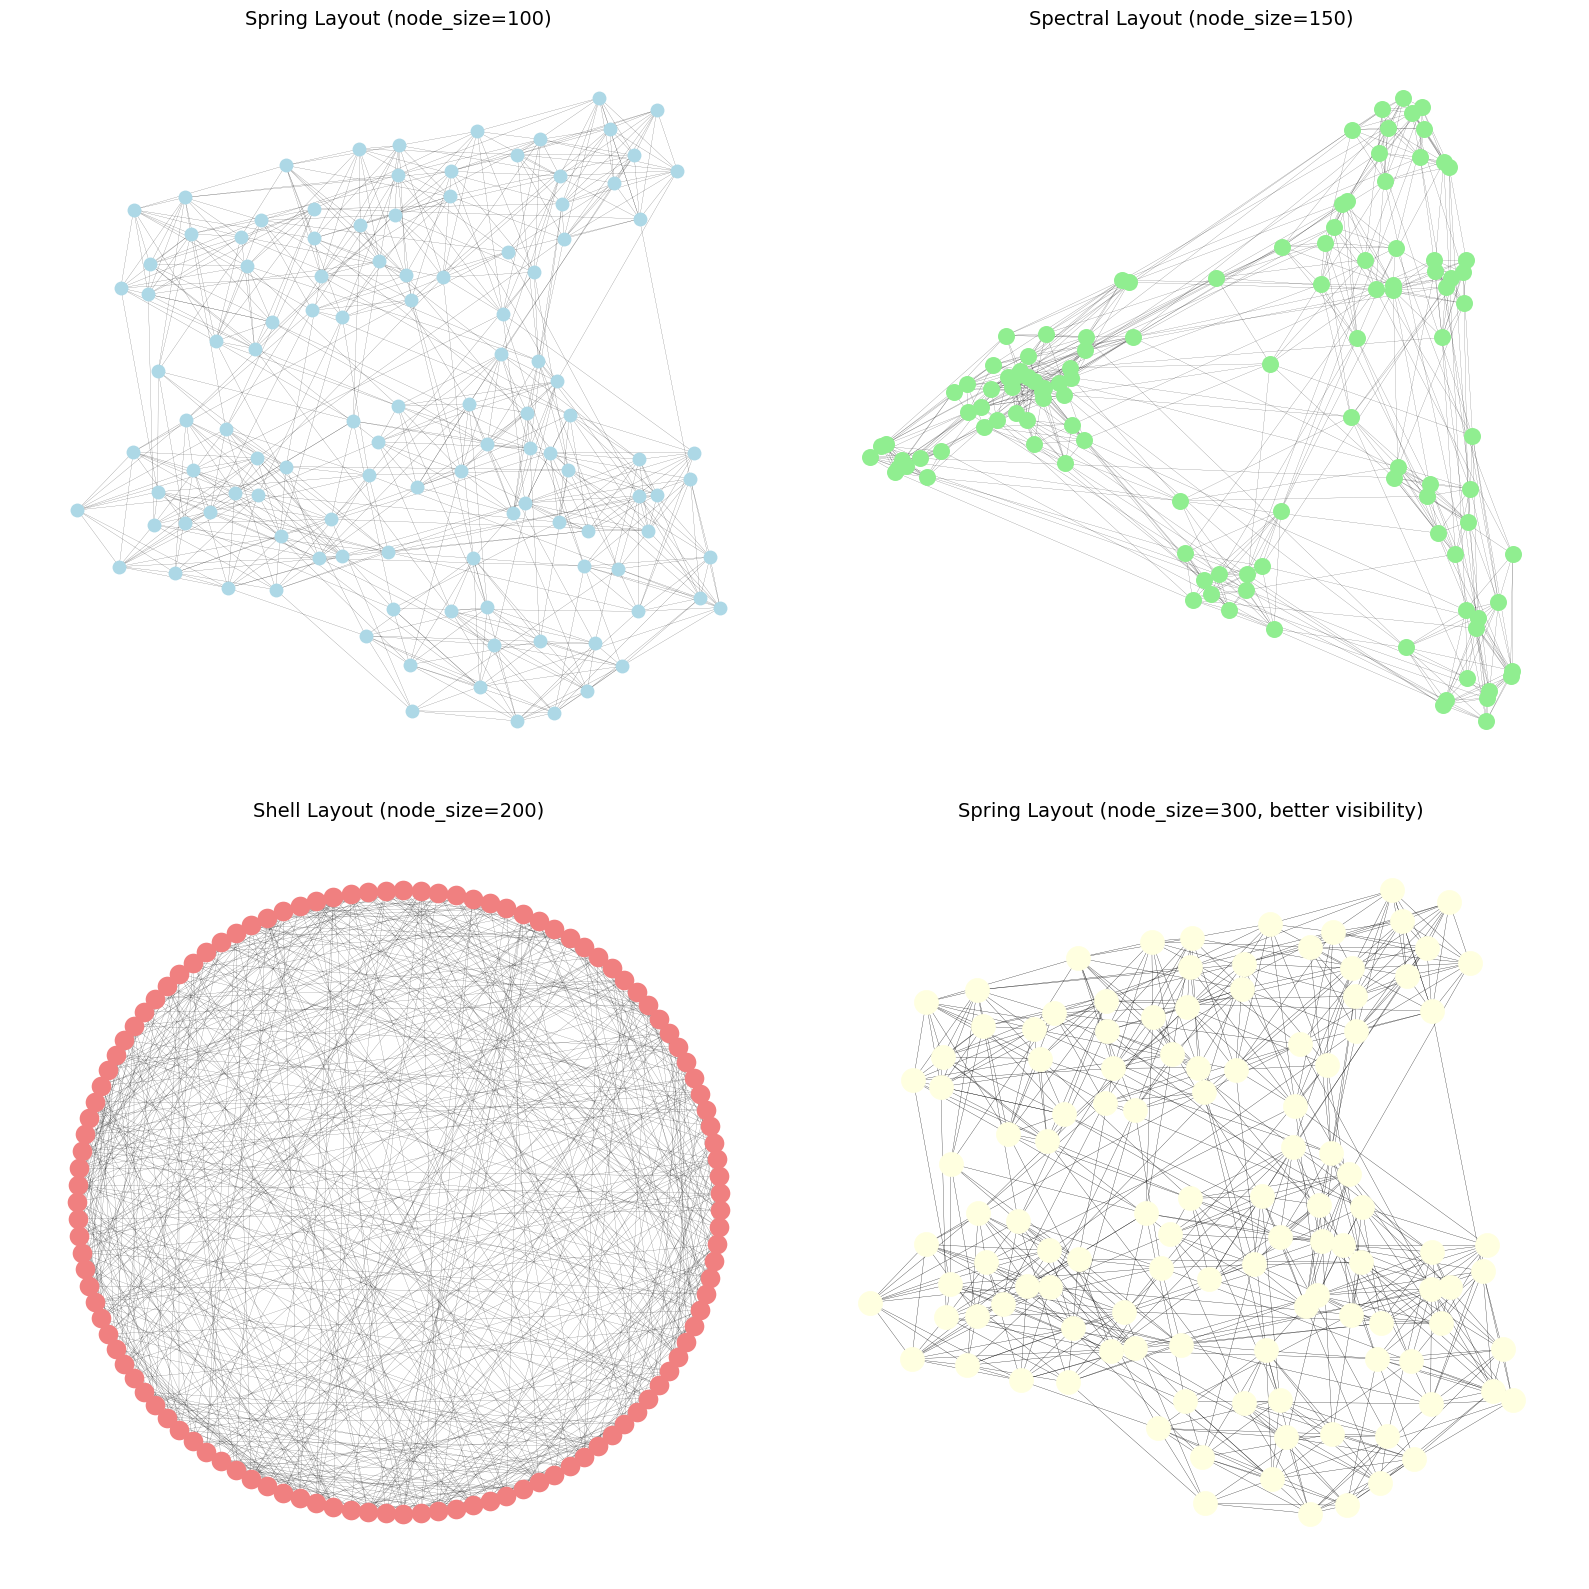


Graph Information:
Number of nodes: 115
Number of edges: 613
Node connectivity: 7
Average degree: 10.66

Centrality Measures:

Top 5 by Degree Centrality:
  BrighamYoung         0.1053
  FloridaState         0.1053
  Iowa                 0.1053
  KansasState          0.1053
  TexasTech            0.1053

Top 5 by Betweenness Centrality:
  NotreDame            0.0335
  BrighamYoung         0.0325
  Navy                 0.0292
  LouisianaTech        0.0288
  CentralMichigan      0.0252

Top 5 by Closeness Centrality:
  LouisianaTech        0.4368
  Navy                 0.4351
  Tulsa                0.4302
  Indiana              0.4270
  PennState            0.4254

Top 5 by Eigenvector Centrality:
  Nevada               0.1277
  SouthernMethodist    0.1226
  Tulsa                0.1213
  SouthernCalifornia   0.1207
  SanJoseState         0.1199


In [33]:
# Project Plot Football League

# Explore amending the code to do the following:
# 1. Visualise the graph using different layouts (spring, spectral, shell) 
# 2. Try different node sizes to identify optimal view
# 3. Print graph info using methods: 'number_of_nodes', 'number_of_edges', 'node_connectivity'
# 4. (Optional) Print graph centrality measure using methods: 'degree_centrality', 'betweenness_centrality', 'closeness_centrality', etc.

import matplotlib.pyplot as plt
import networkx as nx

# 1. Visualise the graph using different layouts
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Spring layout
pos_spring = nx.spring_layout(G, seed=1969)
nx.draw(G, pos_spring, node_color="lightblue", node_size=100, linewidths=0, width=0.1, ax=axes[0, 0])
axes[0, 0].set_title("Spring Layout (node_size=100)", fontsize=14)

# Spectral layout
pos_spectral = nx.spectral_layout(G)
nx.draw(G, pos_spectral, node_color="lightgreen", node_size=150, linewidths=0, width=0.1, ax=axes[0, 1])
axes[0, 1].set_title("Spectral Layout (node_size=150)", fontsize=14)

# Shell layout
pos_shell = nx.shell_layout(G)
nx.draw(G, pos_shell, node_color="lightcoral", node_size=200, linewidths=0, width=0.1, ax=axes[1, 0])
axes[1, 0].set_title("Shell Layout (node_size=200)", fontsize=14)

# 2. Spring layout with larger node size for better visibility
nx.draw(G, pos_spring, node_color="lightyellow", node_size=300, linewidths=0.5, width=0.2, ax=axes[1, 1])
axes[1, 1].set_title("Spring Layout (node_size=300, better visibility)", fontsize=14)

plt.tight_layout()
plt.show()

# 3. Print graph information
print("\n" + "="*50)
print("Graph Information:")
print("="*50)
print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of edges: {G.number_of_edges()}")
print(f"Node connectivity: {nx.node_connectivity(G)}")
print(f"Average degree: {sum(dict(G.degree()).values()) / G.number_of_nodes():.2f}")

# 4. (Optional) Print graph centrality measures
print("\n" + "="*50)
print("Centrality Measures:")
print("="*50)

# Degree centrality - measures the proportion of nodes that a node is connected to
degree_cent = nx.degree_centrality(G)
print("\nTop 5 by Degree Centrality:")
sorted_degree = sorted(degree_cent.items(), key=lambda x: x[1], reverse=True)[:5]
for node, cent in sorted_degree:
    print(f"  {node:20} {cent:.4f}")

# Betweenness centrality - measures how often a node appears on shortest paths
betweenness_cent = nx.betweenness_centrality(G)
print("\nTop 5 by Betweenness Centrality:")
sorted_betweenness = sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True)[:5]
for node, cent in sorted_betweenness:
    print(f"  {node:20} {cent:.4f}")

# Closeness centrality - measures how close a node is to all other nodes
closeness_cent = nx.closeness_centrality(G)
print("\nTop 5 by Closeness Centrality:")
sorted_closeness = sorted(closeness_cent.items(), key=lambda x: x[1], reverse=True)[:5]
for node, cent in sorted_closeness:
    print(f"  {node:20} {cent:.4f}")

# Eigenvector centrality - measures influence based on connections to highly connected nodes
eigenvector_cent = nx.eigenvector_centrality(G, max_iter=1000)
print("\nTop 5 by Eigenvector Centrality:")
sorted_eigenvector = sorted(eigenvector_cent.items(), key=lambda x: x[1], reverse=True)[:5]
for node, cent in sorted_eigenvector:
    print(f"  {node:20} {cent:.4f}")

#### *2. Transport Network*

This example will use Python and NetworkX to develop a graph, which represents a transport network

Major world cities have extensive public transport networks with maps available online. Checking some of those maps might help with this task
- This example has 10 nodes and 10 edges representing 3 lines with their stations
- The provided example is not complete
- The graph and the source code fragments can be used as an example

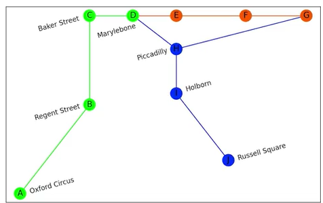

A number of questions can be considered at this stage of the visualisation process, including:
- Colour scheme
- Font and orientation of labels
- Shape and size of nodes
- Orange Line is missing its stations' names, how to reorganise the network in order to add them

Co-ordinates
- Since this is a map, all elements (nodes and labels) need to be positioned at specific locations
- These locations are expected to match, to certain extent, the actual locations of the corresponding stations
- To improve map readability, some compromises in terms of accuracy, are necessary. Can you name some of them? (for example, actual distances and routes between stations)


In [26]:
### Discuss the considerations on colour scheme, font and orientation of labels,
### shape and size of nodes, missing station names


In [27]:
### Discuss the compromises in terms of accuracy that may improve map readability


**Exercise**:

- By using the Python and NetworkX, develop a graph which represents the public transport network of a city of your choice
- Many cities have significant and complex transport networks
    * If this is the case with your choice, you only need to represent a part of this network, for example, specific lines or areas of that city
- Make sure your network with corresponding graph has:
    * at least 15 nodes and 15 edges
    * at least 4 different lines coded with different colours
    * added edge attributes for distance and time
- Your program should be able to calculate the shortest path between two stations based on:
    * number of intermediate stations
    * distance of the journey
    * time of the journey


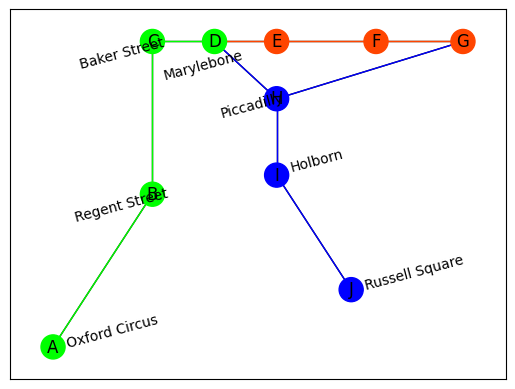

Shortest path:  ['A', 'B', 'C', 'D']


In [29]:
# Public Transport Network

# This example is for guidance only
# It demonstrates the use of the NetworkX library

# Source: CM3005 Data Science (Coursera)
# Week 16 Lab — "Coding Exercise: Public Transport Network"
# Offered by University of London
# Accessed August 2025

import networkx as nx
import matplotlib.pyplot as plt

# Create a graph object
MyGraph = nx.Graph()
MyGB = nx.Graph()
MyGC = nx.Graph()

# Add node (Station on the Green Line)
MyGraph.add_node('A', npos=(10, 10), station='Station A', ccn='#00FF00')
MyGraph.add_node('B', npos=(50, 50), station='Station B', ccn='#00FF00')
MyGraph.add_node('C', npos=(50, 90), station='Station C', ccn='#00FF00')
MyGraph.add_node('D', npos=(75, 90), station='Station D', ccn='#00FF00')

# Orange Line
MyGraph.add_node('E', npos=(100, 90), station='Station E', ccn='#FF4500')
MyGraph.add_node('F', npos=(140, 90), station='Station F', ccn='#FF4500')
MyGraph.add_node('G', npos=(175, 90), station='Station G', ccn='#FF4500')

# Blue Line
MyGraph.add_node('H', npos=(100, 75), station='Station H', ccn='#0000FF')
MyGraph.add_node('I', npos=(100, 55), station='Station I', ccn='#0000FF')
MyGraph.add_node('J', npos=(130, 25), station='Station J', ccn='#0000FF')

# Add edge on the green line (Link between stations A and B)
MyGraph.add_edge('A', 'B', cce='#00FF00')
MyGraph.add_edge('B', 'C', cce='#00FF00')
MyGraph.add_edge('C', 'D', cce='#00FF00')

MyGraph.add_edge('D', 'E', cce='#FF4500')
MyGraph.add_edge('E', 'F', cce='#FF4500')
MyGraph.add_edge('F', 'G', cce='#FF4500')

MyGraph.add_edge('G', 'H', cce='#0000FF')
MyGraph.add_edge('H', 'D', cce='#0000FF')
MyGraph.add_edge('H', 'I', cce='#0000FF')
MyGraph.add_edge('I', 'J', cce='#0000FF')

# Extract attributes from the graph to dictionaries
pos = nx.get_node_attributes(MyGraph, 'npos')
nodecolour = nx.get_node_attributes(MyGraph, 'ccn')
edgecolour = nx.get_edge_attributes(MyGraph, 'cce')

# And then place the dictionary values in array
nodearray = nodecolour.values()
edgearray = edgecolour.values()

# Display the name of the stations
plt.text(15, 10, s='Oxford Circus', rotation=15)
plt.text(18, 43, s='Regent Street', rotation=15)
plt.text(20, 83, s='Baker Street', rotation=15)
plt.text(54, 80, s='Marylebone', rotation=15)
plt.text(77, 70, s='Piccadilly', rotation=15)
plt.text(105, 56, s='Holborn', rotation=15)
plt.text(135, 25, s='Russell Square', rotation=15)

# Draw the network's nodes and edges
nx.draw_networkx(MyGraph, pos, node_color=nodearray)
nx.draw_networkx_edges(MyGraph, pos, edge_color=edgearray)
plt.show()

# Calculate the shortest path based on the number of intermediate nodes
StartNode = input('Enter Start: ')
EndNode = input('Enter End: ')
print('Shortest path: ', nx.shortest_path(MyGraph, source=StartNode, target=EndNode, weight="ccn"))

In [30]:
# Add time attribute to edges and calculate shortest path based on time

import networkx as nx
import matplotlib.pyplot as plt

# Create the transport network graph with time attribute
MyTransportGraph = nx.Graph()

# Add nodes (stations)
MyTransportGraph.add_node('A', npos=(10, 10), station='Station A', ccn='#00FF00')
MyTransportGraph.add_node('B', npos=(50, 50), station='Station B', ccn='#00FF00')
MyTransportGraph.add_node('C', npos=(50, 90), station='Station C', ccn='#00FF00')
MyTransportGraph.add_node('D', npos=(75, 90), station='Station D', ccn='#00FF00')
MyTransportGraph.add_node('E', npos=(100, 90), station='Station E', ccn='#FF4500')
MyTransportGraph.add_node('F', npos=(140, 90), station='Station F', ccn='#FF4500')
MyTransportGraph.add_node('G', npos=(175, 90), station='Station G', ccn='#FF4500')
MyTransportGraph.add_node('H', npos=(100, 75), station='Station H', ccn='#0000FF')
MyTransportGraph.add_node('I', npos=(100, 55), station='Station I', ccn='#0000FF')
MyTransportGraph.add_node('J', npos=(130, 25), station='Station J', ccn='#0000FF')

# Add edges with time attribute (time in minutes)
MyTransportGraph.add_edge('A', 'B', cce='#00FF00', time=5, distance=2.5)
MyTransportGraph.add_edge('B', 'C', cce='#00FF00', time=3, distance=1.5)
MyTransportGraph.add_edge('C', 'D', cce='#00FF00', time=2, distance=1.0)
MyTransportGraph.add_edge('D', 'E', cce='#FF4500', time=4, distance=2.0)
MyTransportGraph.add_edge('E', 'F', cce='#FF4500', time=6, distance=3.0)
MyTransportGraph.add_edge('F', 'G', cce='#FF4500', time=5, distance=2.5)
MyTransportGraph.add_edge('G', 'H', cce='#0000FF', time=3, distance=1.5)
MyTransportGraph.add_edge('H', 'D', cce='#0000FF', time=2, distance=1.0)
MyTransportGraph.add_edge('H', 'I', cce='#0000FF', time=4, distance=2.0)
MyTransportGraph.add_edge('I', 'J', cce='#0000FF', time=7, distance=3.5)

# Calculate the shortest path based on time
StartNode = input('Enter Start Station: ')
EndNode = input('Enter End Station: ')

# Shortest path based on number of stations (no weight)
print('\nShortest path (by stations):', nx.shortest_path(MyTransportGraph, source=StartNode, target=EndNode))

# Shortest path based on time
print('Shortest path (by time):', nx.shortest_path(MyTransportGraph, source=StartNode, target=EndNode, weight='time'))
print('Total journey time:', nx.shortest_path_length(MyTransportGraph, source=StartNode, target=EndNode, weight='time'), 'minutes')

# Shortest path based on distance
print('Shortest path (by distance):', nx.shortest_path(MyTransportGraph, source=StartNode, target=EndNode, weight='distance'))
print('Total distance:', nx.shortest_path_length(MyTransportGraph, source=StartNode, target=EndNode, weight='distance'), 'km')


Shortest path (by stations): ['A', 'B', 'C', 'D', 'H']
Shortest path (by time): ['A', 'B', 'C', 'D', 'H']
Total journey time: 12 minutes
Shortest path (by distance): ['A', 'B', 'C', 'D', 'H']
Total distance: 6.0 km


### 8.2.4 Challenges in Network Visualisation

- Large-scale networks visualised in a limited space
    * Examples include population networks, social media, biological networks, chemical structures, and others
- Complex networks (with multiple attributes)
    * Need to 'abstract out' unnecessary data
    * If not 'removed', unnecessary details may obscure important information
- Nodes and edges with different levels of importance
    * Need to emphasise the important elements, which help to convey the main message, for example, most important/connected node